<a href="https://colab.research.google.com/github/nathalialimaaa/PROJETO-SIN-323/blob/main/AgroCheck_Treinamento_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("AgroCheck - Preparando nossa IA! 🌱")

import sys

print("Versão do Python:", sys.version)

AgroCheck - Preparando nossa IA! 🌱
Versão do Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install tensorflow matplotlib scikit-learn


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU disponível:", len(tf.config.list_physical_devices('GPU')) > 0)


TensorFlow: 2.21.0
GPU disponível: False


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU disponível:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow: 2.21.0
GPU disponível: True


In [ ]:
import tensorflow as tf

print("GPU detectada:")
print(tf.config.list_physical_devices('GPU'))

GPU detectada:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow_datasets as tfds

print("TensorFlow Datasets:", tfds.__version__)
print("Biblioteca carregada com sucesso! 🌽")

TensorFlow Datasets: 4.9.10
Biblioteca carregada com sucesso! 🌽


In [ ]:
import tensorflow_datasets as tfds

dataset = tfds.builder("plant_village")

print("Base encontrada!")
print("Versão:", dataset.version)
print("Categorias disponíveis:")
print(dataset.info.features["label"].names)

Base encontrada!
Versão: 1.0.2
Categorias disponíveis:
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Cherry___Powdery_mildew', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___healthy', 'Corn___Northern_Leaf_Blight', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___healthy', 'Strawberry___Leaf_scorch', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___healthy', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___T

In [ ]:
import tensorflow_datasets as tfds

(dataset_treino, dataset_teste), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

print("Imagens carregadas!")
print("Treino:", tfds.as_numpy(dataset_treino.take(1)).__class__)

ModuleNotFoundError: No module named 'importlib_resources'

In [ ]:
!pip install importlib_resources

In [ ]:
import tensorflow_datasets as tfds

(dataset_treino, dataset_teste), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

print("Base carregada com sucesso!")
print("Imagens de treino:", info.splits["train"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.OIZ0RD_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Base carregada com sucesso!
Imagens de treino: 54303


In [ ]:
import tensorflow as tf

categorias = [
    "Corn___healthy",
    "Corn___Common_rust",
    "Corn___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn___Northern_Leaf_Blight"
]

nomes = info.features["label"].names

for categoria in categorias:
    indice = nomes.index(categoria)

    treino = dataset_treino.filter(
        lambda imagem, rotulo: tf.equal(rotulo, indice)
    )

    teste = dataset_teste.filter(
        lambda imagem, rotulo: tf.equal(rotulo, indice)
    )

    qtd_treino = treino.reduce(
        tf.constant(0),
        lambda total, _: total + 1
    ).numpy()

    qtd_teste = teste.reduce(
        tf.constant(0),
        lambda total, _: total + 1
    ).numpy()

    print(f"\n{categoria}")
    print("Treino:", qtd_treino)
    print("Teste:", qtd_teste)


Corn___healthy
Treino: 939
Teste: 223

Corn___Common_rust
Treino: 953
Teste: 239

Corn___Cercospora_leaf_spot Gray_leaf_spot
Treino: 405
Teste: 108

Corn___Northern_Leaf_Blight
Treino: 788
Teste: 197


In [ ]:
nomes_portugues = {
    "Corn___healthy": "Milho saudável",
    "Corn___Common_rust": "Ferrugem comum",
    "Corn___Cercospora_leaf_spot Gray_leaf_spot": "Mancha cinzenta",
    "Corn___Northern_Leaf_Blight": "Helmintosporiose"
}

for ingles, portugues in nomes_portugues.items():
    print(f"{ingles} → {portugues}")

Corn___healthy → Milho saudável
Corn___Common_rust → Ferrugem comum
Corn___Cercospora_leaf_spot Gray_leaf_spot → Mancha cinzenta
Corn___Northern_Leaf_Blight → Helmintosporiose


In [ ]:
classes = [
    "Milho saudável",
    "Ferrugem comum",
    "Mancha cinzenta",
    "Helmintosporiose"
]

print("Classes do AgroCheck:")

for i, classe in enumerate(classes):
    print(i, "-", classe)

Classes do AgroCheck:
0 - Milho saudável
1 - Ferrugem comum
2 - Mancha cinzenta
3 - Helmintosporiose


In [ ]:
TAMANHO_IMAGEM = (224, 224)

def preparar_imagem(imagem, rotulo):
    imagem = tf.image.resize(imagem, TAMANHO_IMAGEM)
    imagem = tf.cast(imagem, tf.float32)

    return imagem, rotulo

print("Configuração das imagens:")
print("Tamanho:", TAMANHO_IMAGEM)
print("Formato: RGB")
print("Preparação concluída! 🌱")

Configuração das imagens:
Tamanho: (224, 224)
Formato: RGB
Preparação concluída! 🌱


In [ ]:
classes_originais = [
    "Corn___healthy",
    "Corn___Common_rust",
    "Corn___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn___Northern_Leaf_Blight"
]

indices_classes = [
    nomes.index(classe)
    for classe in classes_originais
]

print("Índices das quatro classes:", indices_classes)

Índices das quatro classes: [9, 8, 7, 10]


In [ ]:
def filtrar_milho(imagem, rotulo):
    return tf.reduce_any(
        tf.equal(rotulo, indices_classes)
    )

treino_milho = dataset_treino.filter(filtrar_milho)
teste_milho = dataset_teste.filter(filtrar_milho)

print("Imagens de milho separadas com sucesso! 🌽")

Imagens de milho separadas com sucesso! 🌽


In [ ]:
def converter_rotulo(imagem, rotulo):
    novo_rotulo = tf.argmax(
        tf.cast(tf.equal(rotulo, indices_classes), tf.int32)
    )

    imagem = preparar_imagem(imagem, novo_rotulo)

    return imagem

treino_preparado = treino_milho.map(
    converter_rotulo
)

teste_preparado = teste_milho.map(
    converter_rotulo
)

print("Imagens e categorias preparadas! 🌱")

Imagens e categorias preparadas! 🌱


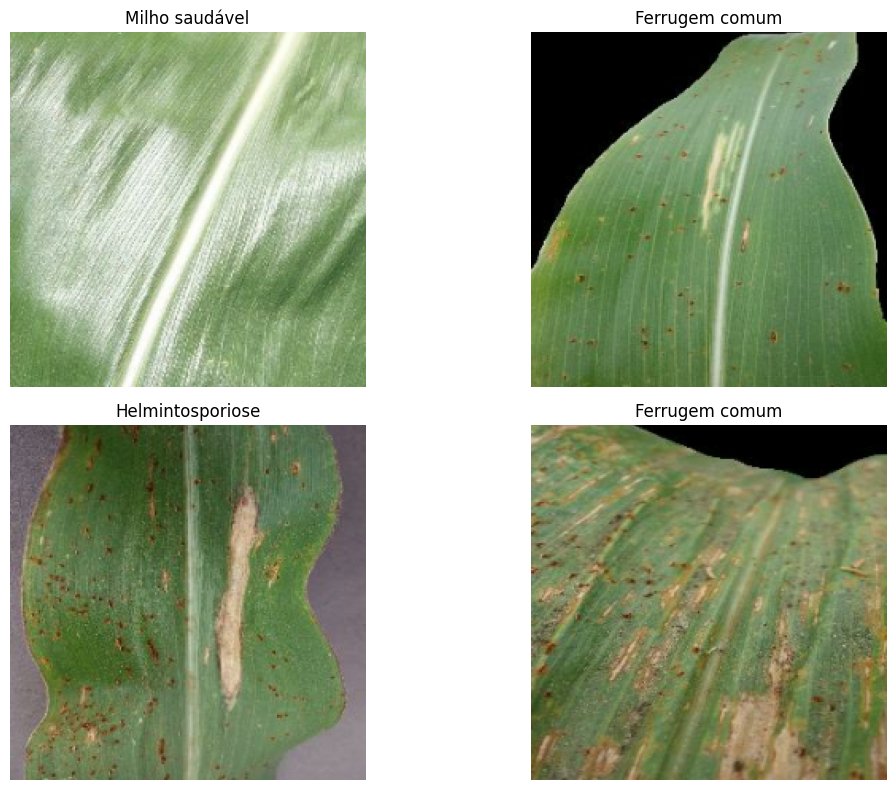

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i, (imagem, rotulo) in enumerate(treino_preparado.take(4)):
    plt.subplot(2, 2, i + 1)

    plt.imshow(imagem.numpy().astype("uint8"))

    plt.title(classes[int(rotulo.numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
TAMANHO_LOTE = 32

treino_final = (
    treino_preparado
    .shuffle(1000)
    .batch(TAMANHO_LOTE)
    .prefetch(tf.data.AUTOTUNE)
)

teste_final = (
    teste_preparado
    .batch(TAMANHO_LOTE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Dados organizados para treinamento! 🌱")

Dados organizados para treinamento! 🌱


In [ ]:
for imagens, rotulos in treino_final.take(1):

    print("Formato das imagens:", imagens.shape)
    print("Formato dos rótulos:", rotulos.shape)

    print("\nPrimeiros rótulos:")

    for rotulo in rotulos[:10]:
        numero = int(rotulo.numpy())
        print(numero, "-", classes[numero])

Formato das imagens: (32, 224, 224, 3)
Formato dos rótulos: (32,)

Primeiros rótulos:
0 - Milho saudável
1 - Ferrugem comum
2 - Mancha cinzenta
1 - Ferrugem comum
0 - Milho saudável
1 - Ferrugem comum
0 - Milho saudável
1 - Ferrugem comum
2 - Mancha cinzenta
2 - Mancha cinzenta


In [ ]:
# Embaralhar os dados
dados_embaralhados = treino_preparado.shuffle(
    3085,
    seed=42,
    reshuffle_each_iteration=False
)

# Separar 20% para validação
dados_validacao = dados_embaralhados.take(617)

# Os outros 80% continuam para treinamento
dados_treino = dados_embaralhados.skip(617)

# Organizar em lotes
treino_final = (
    dados_treino
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

validacao_final = (
    dados_validacao
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

print("Treinamento e validação separados! 🌱")

Treinamento e validação separados! 🌱


In [ ]:
# Carregar a MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Congelar as camadas já treinadas
base_model.trainable = False

# Construir o modelo AgroCheck
modelo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    # Preparar os pixels para a MobileNetV2
    tf.keras.layers.Rescaling(1./127.5, offset=-1),

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.2),

    # 4 classes de doenças do milho
    tf.keras.layers.Dense(4, activation="softmax")
])

# Configurar o aprendizado
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Mostrar a estrutura
modelo.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
historico = modelo.fit(
    treino_final,
    validation_data=validacao_final,
    epochs=10
)

Epoch 1/10
     78/Unknown 61s 222ms/step - accuracy: 0.7405 - loss: 0.6220

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


78/78 ━━━━━━━━━━━━━━━━━━━━ 98s 701ms/step - accuracy: 0.8456 - loss: 0.3868 - val_accuracy: 0.9384 - val_loss: 0.1738
Epoch 2/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 90s 294ms/step - accuracy: 0.9412 - loss: 0.1652 - val_accuracy: 0.9465 - val_loss: 0.1482
Epoch 3/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 41s 293ms/step - accuracy: 0.9502 - loss: 0.1354 - val_accuracy: 0.9417 - val_loss: 0.1389
Epoch 4/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 41s 294ms/step - accuracy: 0.9623 - loss: 0.1134 - val_accuracy: 0.9465 - val_loss: 0.1343
Epoch 5/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 41s 275ms/step - accuracy: 0.9635 - loss: 0.1031 - val_accuracy: 0.9417 - val_loss: 0.1315
Epoch 6/10
77/78 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9631 - loss: 0.1038

KeyboardInterrupt: 

In [ ]:
treino_final = (
    dados_treino
    .batch(32)
    .repeat()
    .prefetch(tf.data.AUTOTUNE)
)

validacao_final = (
    dados_validacao
    .batch(32)
    .repeat()
    .prefetch(tf.data.AUTOTUNE)
)

print("Dados preparados para continuar!")

Dados preparados para continuar!


In [ ]:
historico = modelo.fit(
    treino_final,
    validation_data=validacao_final,
    steps_per_epoch=77,
    validation_steps=20,
    initial_epoch=5,
    epochs=10
)

Epoch 6/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 42s 274ms/step - accuracy: 0.9659 - loss: 0.0827 - val_accuracy: 0.9384 - val_loss: 0.1296
Epoch 7/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 61s 808ms/step - accuracy: 0.9729 - loss: 0.0823 - val_accuracy: 0.9417 - val_loss: 0.1295
Epoch 8/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.9709 - loss: 0.0800 - val_accuracy: 0.9433 - val_loss: 0.1325
Epoch 9/10
76/77 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9766 - loss: 0.0703

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("GPU disponível:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow: 2.21.0
GPU disponível: True


In [ ]:
(dataset_treino, dataset_teste), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

print("Dataset carregado novamente! 🌱")

Dataset carregado novamente! 🌱


In [ ]:
nomes_portugues = {
    "Corn___healthy": "Milho saudável",
    "Corn___Common_rust": "Ferrugem comum",
    "Corn___Cercospora_leaf_spot Gray_leaf_spot": "Mancha cinzenta",
    "Corn___Northern_Leaf_Blight": "Helmintosporiose"
}

classes_originais = list(nomes_portugues.keys())

classes = list(nomes_portugues.values())

nomes = info.features["label"].names

indices_classes = [
    nomes.index(classe)
    for classe in classes_originais
]

print("Classes recuperadas:")
for i, classe in enumerate(classes):
    print(i, "-", classe)

print("Índices:", indices_classes)

Classes recuperadas:
0 - Milho saudável
1 - Ferrugem comum
2 - Mancha cinzenta
3 - Helmintosporiose
Índices: [9, 8, 7, 10]


In [ ]:
def filtrar_milho(imagem, rotulo):
    return tf.reduce_any(
        tf.equal(rotulo, indices_classes)
    )

treino_milho = dataset_treino.filter(filtrar_milho)
teste_milho = dataset_teste.filter(filtrar_milho)

print("Imagens de milho filtradas! 🌱")

Imagens de milho filtradas! 🌱


In [ ]:
TAMANHO_IMAGEM = (224, 224)

def preparar_dados(imagem, rotulo):
    novo_rotulo = tf.argmax(
        tf.cast(
            tf.equal(rotulo, indices_classes),
            tf.int32
        )
    )

    imagem = tf.image.resize(imagem, TAMANHO_IMAGEM)
    imagem = tf.cast(imagem, tf.float32)

    return imagem, novo_rotulo

treino_preparado = treino_milho.map(
    preparar_dados,
    num_parallel_calls=1
)

teste_preparado = teste_milho.map(
    preparar_dados,
    num_parallel_calls=1
)

print("Imagens preparadas! 🌱")

Imagens preparadas! 🌱


In [ ]:
dados_embaralhados = treino_preparado.shuffle(
    buffer_size=500,
    seed=42,
    reshuffle_each_iteration=False
)

dados_validacao = dados_embaralhados.take(617)
dados_treino = dados_embaralhados.skip(617)

print("Treinamento e validação separados! 🌱")

Treinamento e validação separados! 🌱


In [ ]:
TAMANHO_LOTE = 16

treino_final = (
    dados_treino
    .batch(TAMANHO_LOTE)
    .prefetch(1)
)

validacao_final = (
    dados_validacao
    .batch(TAMANHO_LOTE)
    .prefetch(1)
)

teste_final = (
    teste_preparado
    .batch(TAMANHO_LOTE)
    .prefetch(1)
)

print("Dados organizados para treinamento! 🌱")

Dados organizados para treinamento! 🌱


In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

modelo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Rescaling(1./127.5, offset=-1),

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(4, activation="softmax")
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo AgroCheck criado com sucesso! 🌱")

Modelo AgroCheck criado com sucesso! 🌱


In [ ]:
historico = modelo.fit(
    treino_final,
    validation_data=validacao_final,
    epochs=1
)

    155/Unknown 59s 181ms/step - accuracy: 0.7298 - loss: 0.6683

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


155/155 ━━━━━━━━━━━━━━━━━━━━ 83s 338ms/step - accuracy: 0.8460 - loss: 0.3986 - val_accuracy: 0.9352 - val_loss: 0.1668


In [ ]:
treino_final = (
    dados_treino
    .batch(16)
    .repeat()
    .prefetch(1)
)

validacao_final = (
    dados_validacao
    .batch(16)
    .repeat()
    .prefetch(1)
)

print("Dados preparados para treinamento contínuo!")

Dados preparados para treinamento contínuo!


In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "agrocheck_melhor.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

historico = modelo.fit(
    treino_final,
    validation_data=validacao_final,
    steps_per_epoch=155,
    validation_steps=39,
    initial_epoch=1,
    epochs=10,
    callbacks=callbacks
)

Epoch 2/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.9370 - loss: 0.1688
Epoch 2: val_loss improved from None to 0.13915, saving model to agrocheck_melhor.keras

Epoch 2: finished saving model to agrocheck_melhor.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 37s 191ms/step - accuracy: 0.9368 - loss: 0.1665 - val_accuracy: 0.9449 - val_loss: 0.1391
Epoch 3/10
154/155 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.9470 - loss: 0.1356
Epoch 3: val_loss improved from 0.13915 to 0.13442, saving model to agrocheck_melhor.keras

Epoch 3: finished saving model to agrocheck_melhor.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 31s 200ms/step - accuracy: 0.9465 - loss: 0.1369 - val_accuracy: 0.9433 - val_loss: 0.1344
Epoch 4/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.9629 - loss: 0.1081
Epoch 4: val_loss improved from 0.13442 to 0.12591, saving model to agrocheck_melhor.keras

Epoch 4: finished saving model to agrocheck_melhor.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 31s 200ms/step - accurac

In [ ]:
print("Treinamento finalizado!")
print("Melhor precisão de validação:",
      max(historico.history["val_accuracy"]))

print("Épocas concluídas:",
      len(historico.history["accuracy"]))

Treinamento finalizado!
Melhor precisão de validação: 0.9513776302337646
Épocas concluídas: 6


In [ ]:
resultado_teste = modelo.evaluate(teste_final)

print("Precisão no conjunto de teste:", resultado_teste[1] * 100, "%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 453ms/step - accuracy: 0.9505 - loss: 0.1377
Precisão no conjunto de teste: 95.04563212394714 %


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Respostas verdadeiras
y_verdadeiro = np.concatenate([
    rotulos.numpy()
    for imagens, rotulos in teste_final
])

# Previsões da IA
previsoes = modelo.predict(teste_final, verbose=0)

y_previsto = np.argmax(previsoes, axis=1)

# Relatório por doença
print(classification_report(
    y_verdadeiro,
    y_previsto,
    target_names=classes,
    digits=4
))

                  precision    recall  f1-score   support

  Milho saudável     1.0000    1.0000    1.0000       223
  Ferrugem comum     0.9958    1.0000    0.9979       239
 Mancha cinzenta     0.9080    0.7315    0.8103       108
Helmintosporiose     0.8664    0.9543    0.9082       197

        accuracy                         0.9505       767
       macro avg     0.9426    0.9214    0.9291       767
    weighted avg     0.9514    0.9505    0.9491       767



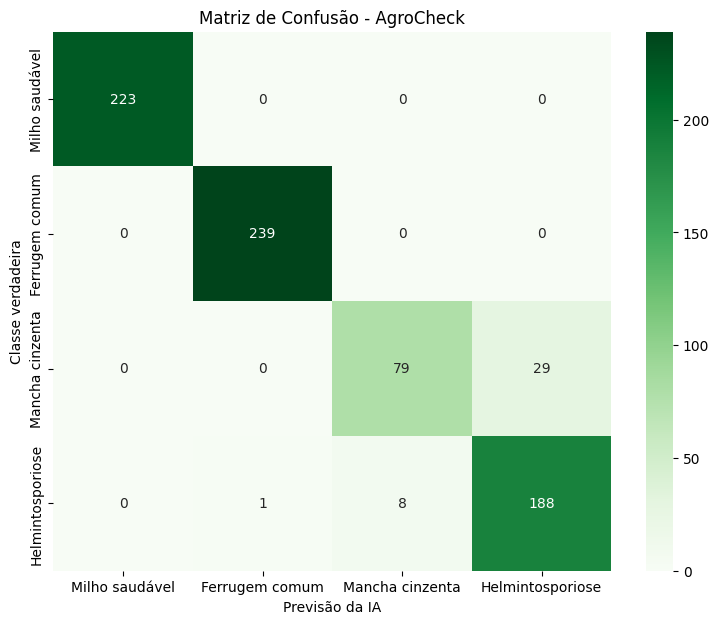

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(
    y_verdadeiro,
    y_previsto
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Previsão da IA")
plt.ylabel("Classe verdadeira")
plt.title("Matriz de Confusão - AgroCheck")
plt.show()

In [ ]:
contagem_classes = np.zeros(4, dtype=int)

for imagens, rotulos in dados_treino:
    contagem_classes[rotulos.numpy()] += 1

for nome, quantidade in zip(classes, contagem_classes):
    print(f"{nome}: {quantidade} imagens")

Milho saudável: 744 imagens
Ferrugem comum: 756 imagens
Mancha cinzenta: 315 imagens
Helmintosporiose: 653 imagens


In [ ]:
pesos_classes = {
    0: 0.8293,  # Milho saudável
    1: 0.8161,  # Ferrugem comum
    2: 1.9587,  # Mancha cinzenta
    3: 0.9449   # Helmintosporiose
}

historico_balanceado = modelo.fit(
    treino_final,
    validation_data=validacao_final,
    steps_per_epoch=155,
    validation_steps=39,
    epochs=5,
    class_weight=pesos_classes,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ]
)

Epoch 1/5
155/155 ━━━━━━━━━━━━━━━━━━━━ 49s 204ms/step - accuracy: 0.9627 - loss: 0.1272 - val_accuracy: 0.9530 - val_loss: 0.1183
Epoch 2/5
155/155 ━━━━━━━━━━━━━━━━━━━━ 33s 213ms/step - accuracy: 0.9639 - loss: 0.1218 - val_accuracy: 0.9530 - val_loss: 0.1147
Epoch 3/5
155/155 ━━━━━━━━━━━━━━━━━━━━ 30s 196ms/step - accuracy: 0.9643 - loss: 0.1099 - val_accuracy: 0.9481 - val_loss: 0.1207
Epoch 4/5
155/155 ━━━━━━━━━━━━━━━━━━━━ 32s 210ms/step - accuracy: 0.9676 - loss: 0.1051 - val_accuracy: 0.9546 - val_loss: 0.1207


In [ ]:
previsoes = modelo.predict(teste_final, verbose=0)
y_previsto = np.argmax(previsoes, axis=1)

print(classification_report(
    y_verdadeiro,
    y_previsto,
    target_names=classes,
    digits=4
))

                  precision    recall  f1-score   support

  Milho saudável     1.0000    1.0000    1.0000       223
  Ferrugem comum     0.9958    1.0000    0.9979       239
 Mancha cinzenta     0.8627    0.8148    0.8381       108
Helmintosporiose     0.9010    0.9239    0.9123       197

        accuracy                         0.9544       767
       macro avg     0.9399    0.9347    0.9371       767
    weighted avg     0.9539    0.9544    0.9540       767



/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [ ]:
modelo.save("agrocheck_modelo.keras")

print("Modelo salvo com sucesso!")

NameError: name 'modelo' is not defined

In [ ]:
import os

print(os.listdir())

['.config', 'sample_data']


In [ ]:
tfds.load("plant_village")

NameError: name 'tfds' is not defined

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("GPU disponível:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow: 2.21.0
GPU disponível: True


In [ ]:
(dataset_treino, dataset_teste), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

print("Dataset carregado!")
print("Total de imagens:", info.splits["train"].num_examples)

ModuleNotFoundError: No module named 'importlib_resources'

In [ ]:
!pip install -q importlib_resources

In [ ]:
(dataset_treino, dataset_teste), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

print("Dataset carregado!")
print("Total de imagens:", info.splits["train"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.YN8L8V_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Dataset carregado!
Total de imagens: 54303


In [ ]:
nomes_portugues = {
    "Corn___healthy": "Milho saudável",
    "Corn___Common_rust": "Ferrugem comum",
    "Corn___Cercospora_leaf_spot Gray_leaf_spot": "Mancha cinzenta",
    "Corn___Northern_Leaf_Blight": "Helmintosporiose"
}

classes_originais = list(nomes_portugues.keys())
classes = list(nomes_portugues.values())

nomes = info.features["label"].names

indices_classes = [
    nomes.index(classe) for classe in classes_originais
]

print("Classes:", classes)
print("Índices:", indices_classes)

Classes: ['Milho saudável', 'Ferrugem comum', 'Mancha cinzenta', 'Helmintosporiose']
Índices: [9, 8, 7, 10]


In [ ]:
def filtrar_milho(imagem, rotulo):
    return tf.reduce_any(
        tf.equal(rotulo, indices_classes)
    )

treino_milho = dataset_treino.filter(filtrar_milho)
teste_milho = dataset_teste.filter(filtrar_milho)

print("Filtro aplicado com sucesso!")

Filtro aplicado com sucesso!


In [ ]:
TAMANHO_IMAGEM = (224, 224)

def preparar_dados(imagem, rotulo):
    novo_rotulo = tf.argmax(
        tf.cast(tf.equal(rotulo, indices_classes), tf.int32)
    )

    imagem = tf.image.resize(imagem, TAMANHO_IMAGEM)
    imagem = tf.cast(imagem, tf.float32)

    return imagem, novo_rotulo

treino_preparado = treino_milho.map(
    preparar_dados,
    num_parallel_calls=1
)

teste_preparado = teste_milho.map(
    preparar_dados,
    num_parallel_calls=1
)

print("Imagens preparadas!")

Imagens preparadas!


In [ ]:
dados_embaralhados = treino_preparado.shuffle(
    buffer_size=500,
    seed=42,
    reshuffle_each_iteration=False
)

dados_validacao = dados_embaralhados.take(617)
dados_treino = dados_embaralhados.skip(617)

print("Treinamento e validação separados!")

Treinamento e validação separados!


In [ ]:
TAMANHO_LOTE = 16

treino_final = (
    dados_treino
    .batch(TAMANHO_LOTE)
    .repeat()
    .prefetch(1)
)

validacao_final = (
    dados_validacao
    .batch(TAMANHO_LOTE)
    .repeat()
    .prefetch(1)
)

teste_final = (
    teste_preparado
    .batch(TAMANHO_LOTE)
    .prefetch(1)
)

print("Dados prontos para o treinamento!")

Dados prontos para o treinamento!


In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

modelo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(4, activation="softmax")
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo AgroCheck reconstruído!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Modelo AgroCheck reconstruído!


In [ ]:
pesos_classes = {
    0: 0.8293,
    1: 0.8161,
    2: 1.9587,
    3: 0.9449
}

print("Pesos das classes configurados!")

Pesos das classes configurados!


In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "agrocheck_melhor.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

historico = modelo.fit(
    treino_final,
    validation_data=validacao_final,
    steps_per_epoch=155,
    validation_steps=39,
    epochs=5,
    class_weight=pesos_classes,
    callbacks=callbacks
)

Epoch 1/5
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.7193 - loss: 0.7455
Epoch 1: val_loss improved from None to 0.17176, saving model to agrocheck_melhor.keras

Epoch 1: finished saving model to agrocheck_melhor.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 99s 429ms/step - accuracy: 0.8400 - loss: 0.4535 - val_accuracy: 0.9384 - val_loss: 0.1718
Epoch 2/5
154/155 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.9362 - loss: 0.2200
Epoch 2: val_loss improved from 0.17176 to 0.14419, saving model to agrocheck_melhor.keras

Epoch 2: finished saving model to agrocheck_melhor.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 30s 198ms/step - accuracy: 0.9380 - loss: 0.2047 - val_accuracy: 0.9481 - val_loss: 0.1442
Epoch 3/5
152/155 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.9507 - loss: 0.1666
Epoch 3: val_loss improved from 0.14419 to 0.13090, saving model to agrocheck_melhor.keras

Epoch 3: finished saving model to agrocheck_melhor.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 32s 206ms/step - accuracy: 

In [ ]:
from google.colab import files

files.download("agrocheck_melhor.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import zipfile
import os
import shutil
import tensorflow as tf
from google.colab import files

# 1. Descompacta o arquivo do seu Google Drive
caminho_zip_drive = "/content/drive/MyDrive/archive.zip"
print("1. Extraindo o dataset...")
with zipfile.ZipFile(caminho_zip_drive, 'r') as zip_ref:
    zip_ref.extractall("/content/todos_dados")

# Identifica de forma inteligente onde as pastas reais de imagens estão
pasta_origem = "/content/todos_dados"
conteudo = os.listdir(pasta_origem)
if len(conteudo) == 1 and os.path.isdir(os.path.join(pasta_origem, conteudo[0])):
    pasta_origem = os.path.join(pasta_origem, conteudo[0])

# 2. Separa apenas as pastas de Milho (Corn) e Cenoura (Carrot)
pasta_filtrada = "/content/dataset_milho_cenoura"
if os.path.exists(pasta_filtrada):
    shutil.rmtree(pasta_filtrada)
os.makedirs(pasta_filtrada, exist_ok=True)

print(f"Buscando pastas de imagens em: {pasta_origem}")
pastas_copiadas = 0
for pasta in os.listdir(pasta_origem):
    if "carrot" in pasta.lower() or "corn" in pasta.lower():
        orig = os.path.join(pasta_origem, pasta)
        dest = os.path.join(pasta_filtrada, pasta)
        if os.path.isdir(orig):
            shutil.copytree(orig, dest, dirs_exist_ok=True)
            print(f"Pasta identificada e copiada: {pasta}")
            pastas_copiadas += 1

print(f"Total de pastas copiadas com sucesso: {pastas_copiadas}")

# 3. Carrega as fotos para o TensorFlow (80% treino / 20% teste)
dados_treino = tf.keras.utils.image_dataset_from_directory(
    pasta_filtrada,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=16
)

dados_validacao = tf.keras.utils.image_dataset_from_directory(
    pasta_filtrada,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=16
)

classes = dados_treino.class_names
print("\nClasses que a IA vai aprender:", classes)

# 4. Constrói e treina a IA (MobileNetV2)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

modelo_novo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(len(classes), activation="softmax")
])

modelo_novo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\n2. Treinando a IA (aguarde alguns minutos)...")
modelo_novo.fit(dados_treino, validation_data=dados_validacao, epochs=10)

# 5. Salva e baixa o arquivo do cérebro da IA
modelo_novo.save("agrocheck_melhor.keras")
files.download("agrocheck_melhor.keras")

1. Extraindo o dataset...
Buscando pastas de imagens em: /content/todos_dados/dataset_clean_final
Pasta identificada e copiada: Carrot__Rotten
Pasta identificada e copiada: Carrot__Healthy
Pasta identificada e copiada: Corn___Northern_Leaf_Blight_Leaf
Pasta identificada e copiada: Corn___Healthy_Leaf
Pasta identificada e copiada: Corn___Gray_Leaf_Spot_Leaf
Pasta identificada e copiada: Corn___Common_Rust_Leaf
Total de pastas copiadas com sucesso: 6
Found 4368 files belonging to 6 classes.
Using 3495 files for training.
Found 4368 files belonging to 6 classes.
Using 873 files for validation.

Classes que a IA vai aprender: ['Carrot__Healthy', 'Carrot__Rotten', 'Corn___Common_Rust_Leaf', 'Corn___Gray_Leaf_Spot_Leaf', 'Corn___Healthy_Leaf', 'Corn___Northern_Leaf_Blight_Leaf']
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

2. Treinando a IA (aguarde alguns minutos)...
Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 119s 432ms/step - accuracy: 0.8129 - loss: 0.4941 - val_accuracy: 0.9061 - val_l

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 🧪 Validando o Modelo Salvo (`.keras`)

O código abaixo carrega o arquivo gerado `agrocheck_melhor.keras`, separa algumas imagens do conjunto de validação, realiza as previsões e plota os resultados com o diagnóstico da IA e a confiança do acerto.

Carregando o modelo salvo...
Modelo carregado com sucesso! 🌱

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


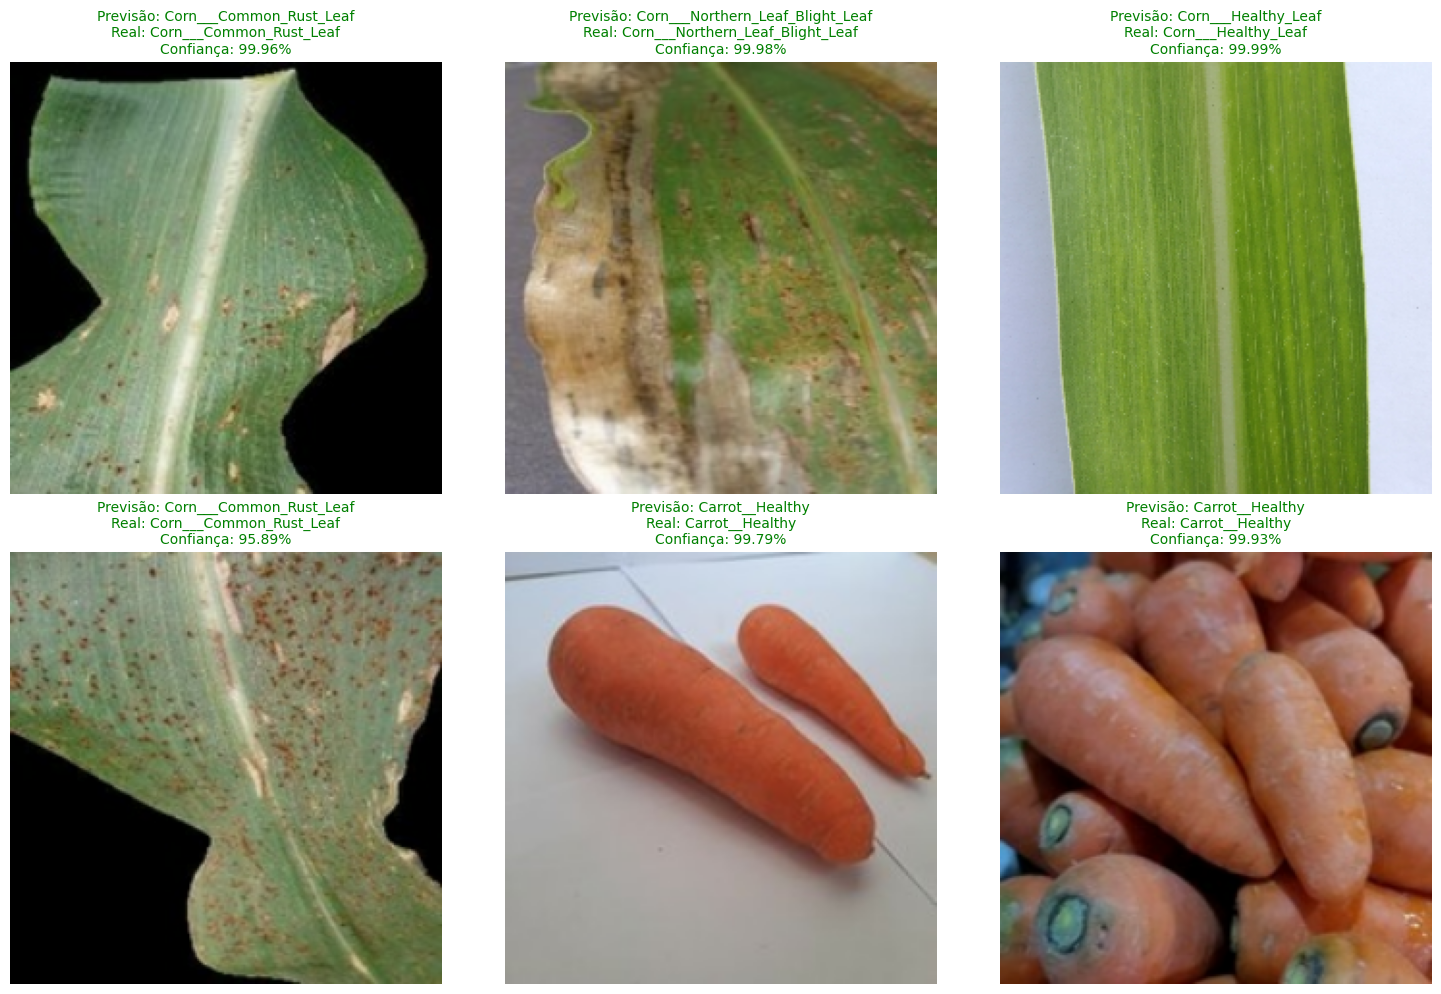

In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# 1. Carrega o modelo treinado que foi salvo no Colab
print("Carregando o modelo salvo...")
modelo_carregado = tf.keras.models.load_model("agrocheck_melhor.keras")
print("Modelo carregado com sucesso! 🌱\n")

# 2. Pega um lote de imagens de validação para teste visual
for imagens_teste, rotulos_teste in dados_validacao.take(1):
    # Realiza a previsão de todo o lote usando o modelo carregado
    previsoes = modelo_carregado.predict(imagens_teste)

    # Configura a visualização
    plt.figure(figsize=(15, 10))

    # Mostra as primeiras 6 imagens e suas classificações
    for i in range(6):
        plt.subplot(2, 3, i + 1)

        # Exibe a imagem
        plt.imshow(imagens_teste[i].numpy().astype("uint8"))

        # Obtém a classe real e a classe prevista pela IA
        classe_real = classes[rotulos_teste[i].numpy()]
        indice_previsto = np.argmax(previsoes[i])
        classe_prevista = classes[indice_previsto]
        confianca = previsoes[i][indice_previsto] * 100

        # Define a cor do título: verde se a IA acertou, vermelho se errou
        cor = "green" if classe_real == classe_prevista else "red"

        plt.title(
            f"Previsão: {classe_prevista}\nReal: {classe_real}\nConfiança: {confianca:.2f}%",
            color=cor,
            fontsize=10
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

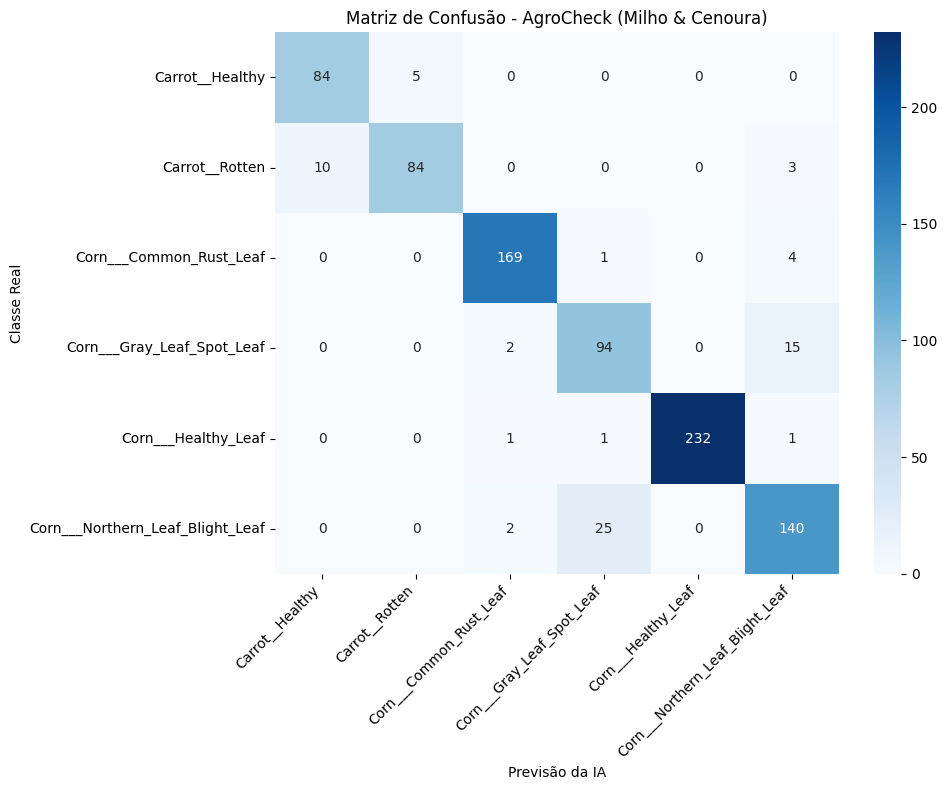

In [8]:
import seaborn as sns

# 4. Plota a Matriz de Confusão de forma visual
matriz_confusao = confusion_matrix(y_real, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_confusao,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Matriz de Confusão - AgroCheck (Milho & Cenoura)")
plt.xlabel("Previsão da IA")
plt.ylabel("Classe Real")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 🚀 Melhorando a Acurácia com Data Augmentation e Fine-Tuning

Vamos criar um novo pipeline de treinamento que inclui camadas de aumento de dados (Data Augmentation) e faremos o ajuste fino (Fine-Tuning) liberando as camadas finais da `MobileNetV2` para treinamento.

In [9]:
import tensorflow as tf

# 1. Definimos uma camada de Data Augmentation para tornar o treino mais robusto
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.1),
])

# 2. Recarregamos o modelo base MobileNetV2
base_model_ft = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Descongelamos as últimas camadas para Fine-Tuning (ajuste fino)
base_model_ft.trainable = True
# Deixamos apenas as últimas 30 camadas treináveis para evitar Overfitting
for layer in base_model_ft.layers[:-30]:
    layer.trainable = False

# 3. Montamos o modelo melhorado
modelo_melhorado = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    data_augmentation,                      # Camada de Aumento de Imagens
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base_model_ft,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),            # Aumentamos levemente o Dropout para evitar Overfitting
    tf.keras.layers.Dense(len(classes), activation="softmax")
])

# 4. Compilamos com uma taxa de aprendizado menor (ideal para Fine-Tuning)
modelo_melhorado.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Novo modelo configurado com Data Augmentation e preparado para Fine-Tuning! 🌱")

Novo modelo configurado com Data Augmentation e preparado para Fine-Tuning! 🌱


In [10]:
# 5. Treinamento do novo modelo com as melhorias aplicadas
historico_melhorado = modelo_melhorado.fit(
    dados_treino,
    validation_data=dados_validacao,
    epochs=8
)

# Salva o novo modelo aprimorado
modelo_melhorado.save("agrocheck_turbinado.keras")
print("Modelo aprimorado treinado e salvo como 'agrocheck_turbinado.keras'! 🏆")

Epoch 1/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 77s 282ms/step - accuracy: 0.5308 - loss: 1.2623 - val_accuracy: 0.6575 - val_loss: 0.9106
Epoch 2/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 65s 235ms/step - accuracy: 0.7931 - loss: 0.6218 - val_accuracy: 0.7503 - val_loss: 0.6278
Epoch 3/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 61s 280ms/step - accuracy: 0.8366 - loss: 0.4690 - val_accuracy: 0.8053 - val_loss: 0.5065
Epoch 4/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 59s 271ms/step - accuracy: 0.8627 - loss: 0.3808 - val_accuracy: 0.8373 - val_loss: 0.4136
Epoch 5/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 51s 231ms/step - accuracy: 0.8755 - loss: 0.3514 - val_accuracy: 0.8637 - val_loss: 0.3431
Epoch 6/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 62s 285ms/step - accuracy: 0.8870 - loss: 0.3043 - val_accuracy: 0.8751 - val_loss: 0.3114
Epoch 7/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 62s 286ms/step - accuracy: 0.9021 - loss: 0.2834 - val_accuracy: 0.8866 - val_loss: 0.2932
Epoch 8/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 82s 285ms/step - accuracy: 0.9041 - loss: 0.2728 - 

### 📊 Avaliação do Modelo Aprimorado (`agrocheck_turbinado.keras`)

Vamos rodar a avaliação detalhada no conjunto de validação para ver as métricas de precisão por classe após as técnicas de Data Augmentation e Fine-Tuning.

🚀 Acurácia Geral do Modelo Turbinado: 89.92%

📈 RELATÓRIO DE CLASSIFICAÇÃO (MODELO TURBINADO):
                                  precision    recall  f1-score   support

                 Carrot__Healthy       0.80      0.97      0.88        89
                  Carrot__Rotten       0.96      0.78      0.86        97
         Corn___Common_Rust_Leaf       0.95      0.98      0.96       174
      Corn___Gray_Leaf_Spot_Leaf       0.71      0.89      0.79       111
             Corn___Healthy_Leaf       0.98      0.99      0.99       235
Corn___Northern_Leaf_Blight_Leaf       0.93      0.72      0.81       167

                        accuracy                           0.90       873
                       macro avg       0.89      0.89      0.88       873
                    weighted avg       0.91      0.90      0.90       873



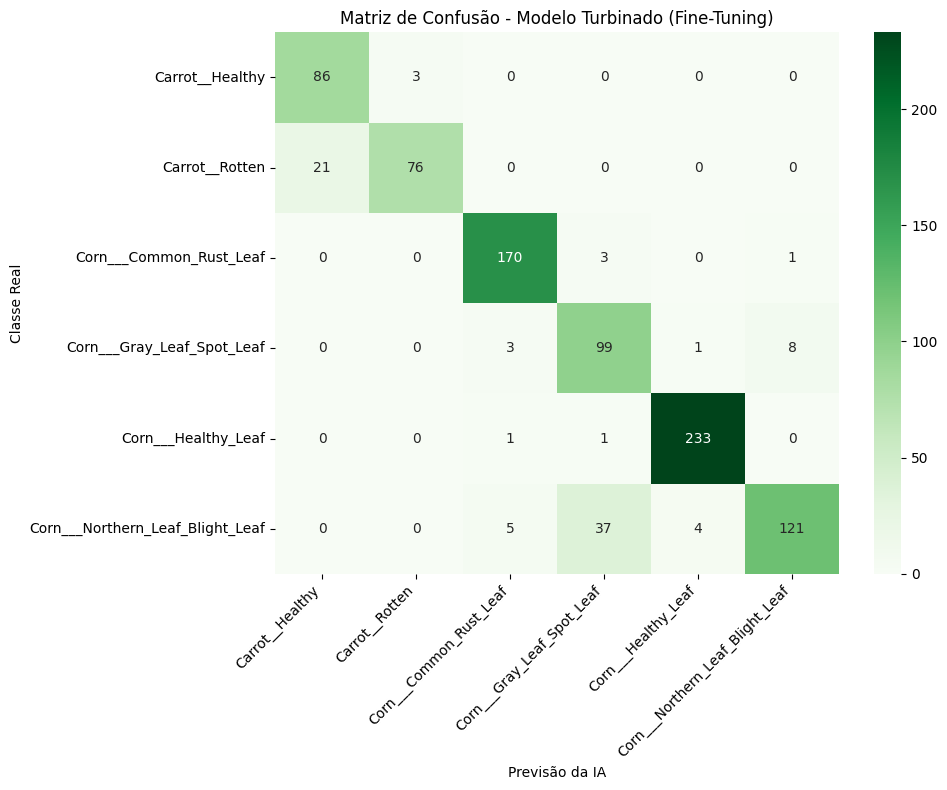

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Avalia o modelo aprimorado diretamente
resultados_turbinado = modelo_melhorado.evaluate(dados_validacao, verbose=0)
print(f"🚀 Acurácia Geral do Modelo Turbinado: {resultados_turbinado[1]*100:.2f}%\n")

# 2. Coleta previsões
y_real_ft = []
y_pred_ft = []

for imagens, rotulos in dados_validacao:
    preds = modelo_melhorado.predict(imagens, verbose=0)
    y_real_ft.extend(rotulos.numpy())
    y_pred_ft.extend(np.argmax(preds, axis=1))

y_real_ft = np.array(y_real_ft)
y_pred_ft = np.array(y_pred_ft)

# 3. Exibe o relatório
print("📈 RELATÓRIO DE CLASSIFICAÇÃO (MODELO TURBINADO):")
print(classification_report(y_real_ft, y_pred_ft, target_names=classes))

# 4. Plota a Matriz de Confusão
matriz_ft = confusion_matrix(y_real_ft, y_pred_ft)
plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_ft,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=classes,
    yticklabels=classes
)
plt.title("Matriz de Confusão - Modelo Turbinado (Fine-Tuning)")
plt.xlabel("Previsão da IA")
plt.ylabel("Classe Real")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 💾 Disponibilizando o Modelo Turbinado para Uso e Download

Agora vamos carregar oficialmente o `agrocheck_turbinado.keras` na nossa variável ativa de validação e iniciar o download do arquivo para a sua máquina física.

In [12]:
from google.colab import files

# 1. Atualiza a variável do modelo carregado para apontar para a versão turbinada
print("Carregando a versão turbinada do AgroCheck...")
modelo_carregado = tf.keras.models.load_model("agrocheck_turbinado.keras")
print("Modelo turbinado carregado com sucesso e ativo para testes! 🚀🌱\n")

# 2. Faz o download automático do arquivo aprimorado para o seu computador
print("Iniciando o download do arquivo 'agrocheck_turbinado.keras'...")
files.download("agrocheck_turbinado.keras")

Carregando a versão turbinada do AgroCheck...
Modelo turbinado carregado com sucesso e ativo para testes! 🚀🌱

Iniciando o download do arquivo 'agrocheck_turbinado.keras'...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 📈 Gráficos de Evolução do Treino (Acurácia & Perda)

Vamos gerar as curvas de aprendizado do modelo turbinado para analisar visualmente como as métricas progrediram ao longo das épocas de Fine-Tuning.

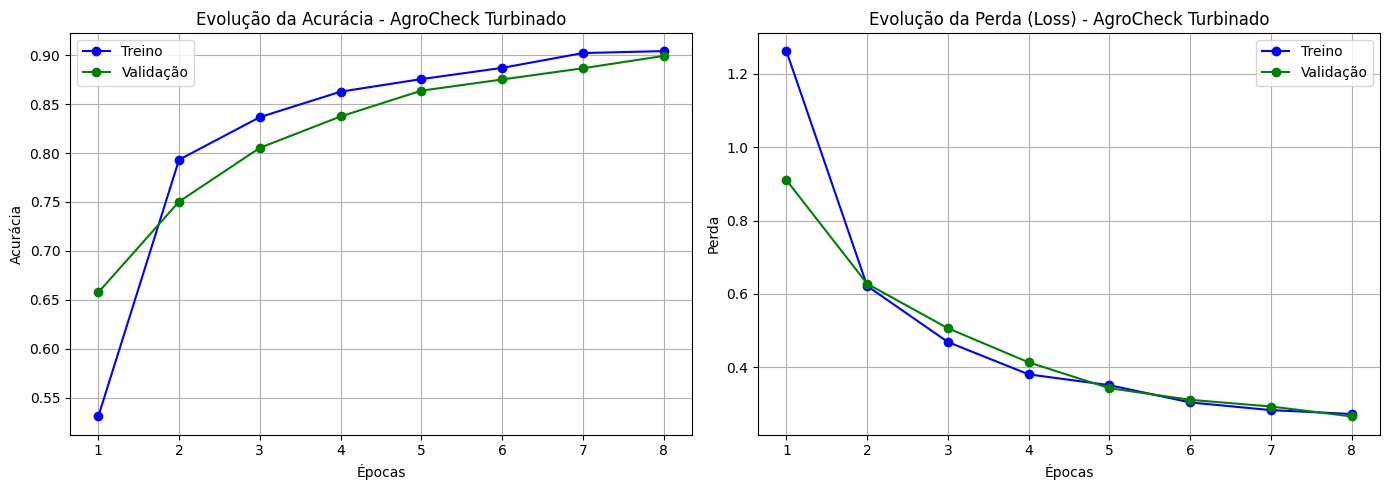

In [15]:
import matplotlib.pyplot as plt

# Obtendo dados do histórico
acc = historico_melhorado.history['accuracy']
val_acc = historico_melhorado.history['val_accuracy']
loss = historico_melhorado.history['loss']
val_loss = historico_melhorado.history['val_loss']
epocas = range(1, len(acc) + 1)

# Criando a figura com subplots para Acurácia e Perda
plt.figure(figsize=(14, 5))

# Subplot 1: Acurácia
plt.subplot(1, 2, 1)
plt.plot(epocas, acc, 'bo-', label='Treino')
plt.plot(epocas, val_acc, 'go-', label='Validação')
plt.title('Evolução da Acurácia - AgroCheck Turbinado')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)

# Subplot 2: Perda (Loss)
plt.subplot(1, 2, 2)
plt.plot(epocas, loss, 'bo-', label='Treino')
plt.plot(epocas, val_loss, 'go-', label='Validação')
plt.title('Evolução da Perda (Loss) - AgroCheck Turbinado')
plt.xlabel('Épocas')
plt.ylabel('Perda')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 🧪 Validação Prática com Novas Imagens e Matriz de Confusão

Rode a célula abaixo para enviar imagens de teste. Você poderá selecionar uma ou várias imagens do seu computador ao mesmo tempo. A IA fará o diagnóstico, exibirá as previsões de forma gráfica e construirá a matriz de confusão correspondente baseada nos arquivos enviados.

In [16]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.metrics import classification_report, confusion_matrix

def testar_novas_imagens_com_matriz():
    print("Selecione uma ou mais imagens de teste do seu computador (pressione Ctrl ou Shift para selecionar várias):")
    upload_arquivos = files.upload()

    if not upload_arquivos:
        print("Nenhuma imagem foi carregada.")
        return

    lista_imagens = list(upload_arquivos.keys())
    provisoes_reais = []
    previsoes_ia = []

    print(f"\nProcessando {len(lista_imagens)} imagem(ns)...\n")

    # Cria espaço para plotar as imagens de teste
    cols = 3
    rows = (len(lista_imagens) + cols - 1) // cols
    plt.figure(figsize=(15, 5 * rows))

    for idx, nome_arquivo in enumerate(lista_imagens):
        # 1. Carrega e prepara a imagem
        img = tf.keras.utils.load_img(nome_arquivo, target_size=(224, 224))
        img_arr = tf.keras.utils.img_to_array(img)
        img_batch = tf.expand_dims(img_arr, 0)

        # 2. Faz a inferência
        pred_probs = modelo_carregado.predict(img_batch, verbose=0)
        indice_predito = np.argmax(pred_probs[0])
        classe_predita = classes[indice_predito]
        confianca = pred_probs[0][indice_predito] * 100

        # 3. Tenta mapear o nome do arquivo a uma classe real para fins de métrica (opcional)
        # Se o nome do arquivo contiver o nome da classe, usamos como classe real, senão usamos como 'Desconhecida'
        classe_real_detectada = "Desconhecida"
        for c in classes:
            if c.lower() in nome_arquivo.lower():
                classe_real_detectada = c
                break

        if classe_real_detectada == "Desconhecida":
            # Se não detectado no nome do arquivo, pergunta via input de texto simples no console
            print(f"Qual a classe real da imagem '{nome_arquivo}'?")
            for num, nome_c in enumerate(classes):
                print(f"[{num}] - {nome_c}")
            escolha = int(input("Digite o número correspondente à classe real: "))
            classe_real_detectada = classes[escolha]

        provisoes_reais.append(classe_real_detectada)
        previsoes_ia.append(classe_predita)

        # 4. Plota no grid
        plt.subplot(rows, cols, idx + 1)
        plt.imshow(img)
        cor_titulo = "green" if classe_real_detectada == classe_predita else "red"
        plt.title(f"Arquivo: {nome_arquivo}\nPrevisão: {classe_predita} ({confianca:.1f}%)\nReal: {classe_real_detectada}", color=cor_titulo, fontsize=10)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    # 5. Gera Relatório de Classificação e Matriz de Confusão das imagens enviadas
    print("\n📈 RELATÓRIO DE CLASSIFICAÇÃO (NOVAS IMAGENS):")
    print(classification_report(provisoes_reais, previsoes_ia, target_names=[c for c in classes if c in provisoes_reais or c in previsoes_ia], zero_division=0))

    # Plot da Matriz de Confusão para as novas fotos enviadas
    classes_presentes = sorted(list(set(provisoes_reais + previsoes_ia)))
    matriz_teste = confusion_matrix(provisoes_reais, previsoes_ia, labels=classes_presentes)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        matriz_teste,
        annot=True,
        fmt="d",
        cmap="Purples",
        xticklabels=classes_presentes,
        yticklabels=classes_presentes
    )
    plt.title("Matriz de Confusão - Validação Prática Local")
    plt.xlabel("Previsão da IA")
    plt.ylabel("Classe Real")
    plt.tight_layout()
    plt.show()

testar_novas_imagens_com_matriz()

Selecione uma ou mais imagens de teste do seu computador (pressione Ctrl ou Shift para selecionar várias):


Nenhuma imagem foi carregada.


### 📊 Relatório de Métricas e Acurácia Detalhada

Vamos calcular a acurácia geral e gerar um relatório completo (Classification Report e Matriz de Confusão) específico para as 6 classes de milho e cenoura do novo modelo.

In [14]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 1. Avalia o modelo diretamente no conjunto de validação
resultados_val = modelo_carregado.evaluate(dados_validacao, verbose=0)
print(f"Acurácia Geral na Validação: {resultados_val[1]*100:.2f}%\n")

# 2. mColeta todas as respostas reais e as previsões do modelo
y_real = []
y_pred = []

for imagens, rotulos in dados_validacao:
    preds = modelo_carregado.predict(imagens, verbose=0)
    y_real.extend(rotulos.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_real = np.array(y_real)
y_pred = np.array(y_pred)

# 3. Exibe o relatório de classificação formatado
print("📈 RELATÓRIO DE CLASSIFICAÇÃO DETALHADO:")
print(classification_report(y_real, y_pred, target_names=classes))

Acurácia Geral na Validação: 89.92%

📈 RELATÓRIO DE CLASSIFICAÇÃO DETALHADO:
                                  precision    recall  f1-score   support

                 Carrot__Healthy       0.80      0.97      0.88        89
                  Carrot__Rotten       0.96      0.78      0.86        97
         Corn___Common_Rust_Leaf       0.95      0.98      0.96       174
      Corn___Gray_Leaf_Spot_Leaf       0.71      0.89      0.79       111
             Corn___Healthy_Leaf       0.98      0.99      0.99       235
Corn___Northern_Leaf_Blight_Leaf       0.93      0.72      0.81       167

                        accuracy                           0.90       873
                       macro avg       0.89      0.89      0.88       873
                    weighted avg       0.91      0.90      0.90       873



In [17]:
# Exibe a lista de classes que o modelo foi treinado para identificar
print("🌿 Classes finais identificadas pelo AgroCheck Turbinado:")
for idx, nome_classe in enumerate(classes):
    print(f"ID {idx}: {nome_classe}")

🌿 Classes finais identificadas pelo AgroCheck Turbinado:
ID 0: Carrot__Healthy
ID 1: Carrot__Rotten
ID 2: Corn___Common_Rust_Leaf
ID 3: Corn___Gray_Leaf_Spot_Leaf
ID 4: Corn___Healthy_Leaf
ID 5: Corn___Northern_Leaf_Blight_Leaf
